In [ ]:
!pip install -q kaggle nltk

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
IMAGE_DIR = "/content/flickr8k/Images"
CAPTION_FILE = "/content/flickr8k/captions.txt"

# If dataset is not already present
if not os.path.exists(IMAGE_DIR):

    from google.colab import files

    print("Upload your kaggle.json file")
    files.upload()

    os.makedirs("/root/.kaggle", exist_ok=True)

    !cp kaggle.json /root/.kaggle/kaggle.json
    !chmod 600 /root/.kaggle/kaggle.json

    print("Downloading Flickr8k...")
    !kaggle datasets download -d adityajn105/flickr8k

    print("Extracting dataset...")
    !mkdir -p /content/flickr8k
    !unzip -q flickr8k.zip -d /content/flickr8k

print("Images folder exists:", os.path.exists(IMAGE_DIR))
print("Caption file exists:", os.path.exists(CAPTION_FILE))
print("Number of images:", len(os.listdir(IMAGE_DIR)))

Upload your kaggle.json file


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/adityajn105/flickr8k
License(s): CC0-1.0
100% 1.04G/1.04G [00:11<00:00, 101MB/s]

Extracting dataset...
Images folder exists: True
Caption file exists: True
Number of images: 8091


In [ ]:
data = pd.read_csv(CAPTION_FILE)

def clean_caption(caption):
    caption = caption.lower()
    caption = re.sub(r"[^a-z ]", "", caption)
    caption = re.sub(r"\s+", " ", caption)
    caption = caption.strip()

    return "startseq " + caption + " endseq"


data["caption"] = data["caption"].apply(clean_caption)

# Get unique images
unique_images = data["image"].unique()

np.random.seed(42)
np.random.shuffle(unique_images)

total = len(unique_images)

train_end = int(0.80 * total)
val_end = int(0.90 * total)

train_images = unique_images[:train_end]
val_images = unique_images[train_end:val_end]
test_images = unique_images[val_end:]

train_data = data[data["image"].isin(train_images)]
val_data = data[data["image"].isin(val_images)]
test_data = data[data["image"].isin(test_images)]

print("Total captions:", len(data))
print("Training images:", len(train_images))
print("Validation images:", len(val_images))
print("Testing images:", len(test_images))

Total captions: 40455
Training images: 6472
Validation images: 809
Testing images: 810


In [ ]:
tokenizer = Tokenizer(
    oov_token="<unk>"
)

tokenizer.fit_on_texts(
    train_data["caption"]
)

vocab_size = len(tokenizer.word_index) + 1

# Find maximum caption length
sequences = tokenizer.texts_to_sequences(
    train_data["caption"]
)

max_length = max(
    len(seq) for seq in sequences
)

print("Vocabulary size:", vocab_size)
print("Maximum caption length:", max_length)

print("\nExample:")
print(train_data.iloc[0]["caption"])

Vocabulary size: 7933
Maximum caption length: 37

Example:
startseq a child in a pink dress is climbing up a set of stairs in an entry way endseq


In [ ]:
vgg = VGG16(
    weights="imagenet",
    include_top=False
)

print("VGG16 loaded!")

# Get all image names
all_images = [
    filename
    for filename in os.listdir(IMAGE_DIR)
    if filename.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

features_file = "/content/vgg16_features.npy"
image_names_file = "/content/vgg16_image_names.npy"

if os.path.exists(features_file):

    print("Loading saved VGG16 features...")

    image_features = np.load(
        features_file,
        allow_pickle=True
    )

    image_names = np.load(
        image_names_file,
        allow_pickle=True
    )

else:

    print("Extracting VGG16 features...")

    image_names = []
    image_features = []

    batch_size = 32

    for start in range(
        0,
        len(all_images),
        batch_size
    ):

        batch_names = all_images[
            start:start + batch_size
        ]

        batch_images = []

        for image_name in batch_names:

            image_path = os.path.join(
                IMAGE_DIR,
                image_name
            )

            image = Image.open(
                image_path
            ).convert("RGB")

            image = image.resize(
                (224, 224)
            )

            batch_images.append(
                np.array(image)
            )

        batch_images = np.array(
            batch_images
        )

        batch_images = preprocess_input(
            batch_images
        )

        batch_features = vgg.predict(
            batch_images,
            verbose=0
        )

        image_names.extend(
            batch_names
        )

        image_features.append(
            batch_features.astype("float16")
        )

        if start % 320 == 0:

            print(
                "Processed:",
                min(
                    start + batch_size,
                    len(all_images)
                ),
                "/",
                len(all_images)
            )

    image_features = np.concatenate(
        image_features,
        axis=0
    )

    image_names = np.array(
        image_names
    )

    np.save(
        features_file,
        image_features
    )

    np.save(
        image_names_file,
        image_names
    )


print("Feature shape:", image_features.shape)

VGG16 loaded!
Extracting VGG16 features...
Processed: 32 / 8091
Processed: 352 / 8091
Processed: 672 / 8091
Processed: 992 / 8091
Processed: 1312 / 8091
Processed: 1632 / 8091
Processed: 1952 / 8091
Processed: 2272 / 8091
Processed: 2592 / 8091
Processed: 2912 / 8091
Processed: 3232 / 8091
Processed: 3552 / 8091
Processed: 3872 / 8091
Processed: 4192 / 8091
Processed: 4512 / 8091
Processed: 4832 / 8091
Processed: 5152 / 8091
Processed: 5472 / 8091
Processed: 5792 / 8091
Processed: 6112 / 8091
Processed: 6432 / 8091
Processed: 6752 / 8091
Processed: 7072 / 8091
Processed: 7392 / 8091
Processed: 7712 / 8091
Processed: 8032 / 8091
Feature shape: (8091, 7, 7, 512)


In [ ]:
feature_dict = {
    name: feature.reshape(49, 512)
    for name, feature in zip(image_names, image_features)
}

class CaptionGenerator(tf.keras.utils.Sequence):

    def __init__(
        self,
        dataframe,
        feature_dict,
        tokenizer,
        max_length,
        batch_size=64,
        shuffle=True
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.feature_dict = feature_dict
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.batch_size = batch_size
        self.shuffle = shuffle

        self.indices = np.arange(len(self.dataframe))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):

        batch_indices = self.indices[
            index * self.batch_size:
            (index + 1) * self.batch_size
        ]

        batch = self.dataframe.iloc[batch_indices]

        images = []
        inputs = []
        targets = []

        for _, row in batch.iterrows():

            image_name = row["image"]
            caption = row["caption"]

            sequence = self.tokenizer.texts_to_sequences(
                [caption]
            )[0]

            input_sequence = sequence[:-1]
            target_sequence = sequence[1:]

            input_sequence = pad_sequences(
                [input_sequence],
                maxlen=self.max_length,
                padding="post"
            )[0]

            target_sequence = pad_sequences(
                [target_sequence],
                maxlen=self.max_length,
                padding="post"
            )[0]

            images.append(self.feature_dict[image_name])
            inputs.append(input_sequence)
            targets.append(target_sequence)

        return (
            (
                np.array(images, dtype="float32"),
                np.array(inputs, dtype="int32")
            ),
            np.array(targets, dtype="int32")
        )

    def on_epoch_end(self):

        if self.shuffle:
            np.random.shuffle(self.indices)


train_generator = CaptionGenerator(
    train_data,
    feature_dict,
    tokenizer,
    max_length
)

val_generator = CaptionGenerator(
    val_data,
    feature_dict,
    tokenizer,
    max_length,
    shuffle=False
)

test_generator = CaptionGenerator(
    test_data,
    feature_dict,
    tokenizer,
    max_length,
    shuffle=False
)

print("Generators ready!")

print(
    "One image feature shape:",
    feature_dict[train_data.iloc[0]["image"]].shape
)

Generators ready!
One image feature shape: (49, 512)


In [ ]:
class BahdanauAttention(layers.Layer):

    def __init__(self, units):
        super().__init__()

        self.W1 = layers.Dense(units)
        self.W2 = layers.Dense(units)
        self.V = layers.Dense(1)

    def call(self, inputs):

        features, queries = inputs

        # Add dimensions for attention calculation
        features = tf.expand_dims(features, axis=1)
        queries = tf.expand_dims(queries, axis=2)

        # Calculate attention score
        score = tf.nn.tanh(
            self.W1(features) + self.W2(queries)
        )

        # Attention weights
        attention_weights = tf.nn.softmax(
            self.V(score),
            axis=2
        )

        # Weighted image features
        context = tf.reduce_sum(
            attention_weights * features,
            axis=2
        )

        return context


# Image input: 49 regions × 512 features
image_input = layers.Input(
    shape=(49, 512),
    name="image_input"
)

# Caption input
caption_input = layers.Input(
    shape=(max_length,),
    name="caption_input"
)


# Project image features
image_features_projected = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(image_input)

image_features_projected = layers.BatchNormalization()(
    image_features_projected
)


# Word embedding
# mask_zero=False to avoid mask broadcasting problem
word_embedding = layers.Embedding(
    vocab_size,
    256
)(caption_input)


# LSTM decoder
lstm_output = layers.LSTM(
    256,
    return_sequences=True,
    dropout=0.3
)(word_embedding)


# Attention
context = BahdanauAttention(256)(
    [image_features_projected, lstm_output]
)


# Combine LSTM + attention
combined = layers.Concatenate()(
    [lstm_output, context]
)


# Dense layer
combined = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(combined)


# Dropout
combined = layers.Dropout(0.3)(combined)


# Final vocabulary prediction
output = layers.Dense(
    vocab_size,
    activation="softmax"
)(combined)


# Create model
model = Model(
    inputs=[image_input, caption_input],
    outputs=output
)

print("Model created successfully!")

model.summary()

Model created successfully!


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ caption_input       │ (None, 37)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_input         │ (None, 49, 512)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 37, 256)   │  2,030,848 │ caption_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 49, 256)   │    131,328 │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 37, 256)   │    525,312 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 49, 256)   │      1,024 │ dense_12[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bahdanau_attention… │ (None, 37, 256)   │    131,841 │ batch_normalizat… │
│ (BahdanauAttention) │                   │            │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 37, 512)   │          0 │ lstm_2[0][0],     │
│ (Concatenate)       │                   │            │ bahdanau_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 37, 256)   │    131,328 │ concatenate_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 37, 256)   │          0 │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 37, 7933)  │  2,038,781 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,990,462 (19.04 MB)

 Trainable params: 4,989,950 (19.04 MB)

 Non-trainable params: 512 (2.00 KB)

In [ ]:
def masked_loss(y_true, y_pred):

    loss = tf.keras.losses.sparse_categorical_crossentropy(
        y_true,
        y_pred
    )

    mask = tf.cast(
        tf.not_equal(y_true, 0),
        tf.float32
    )

    loss = loss * mask

    return tf.reduce_sum(loss) / tf.reduce_sum(mask)


def masked_accuracy(y_true, y_pred):

    predicted = tf.argmax(
        y_pred,
        axis=-1
    )

    predicted = tf.cast(
        predicted,
        tf.int32
    )

    correct = tf.cast(
        tf.equal(
            y_true,
            predicted
        ),
        tf.float32
    )

    mask = tf.cast(
        tf.not_equal(y_true, 0),
        tf.float32
    )

    return tf.reduce_sum(
        correct * mask
    ) / tf.reduce_sum(mask)


optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001,
    clipnorm=1.0
)

model.compile(
    optimizer=optimizer,
    loss=masked_loss,
    metrics=[masked_accuracy]
)


early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=0.00001
)


history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5,
    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/5
506/506 ━━━━━━━━━━━━━━━━━━━━ 46s 76ms/step - loss: 4.4180 - masked_accuracy: 0.2675 - val_loss: 3.6479 - val_masked_accuracy: 0.3411 - learning_rate: 0.0010
Epoch 2/5
506/506 ━━━━━━━━━━━━━━━━━━━━ 38s 75ms/step - loss: 3.4139 - masked_accuracy: 0.3588 - val_loss: 3.3545 - val_masked_accuracy: 0.3741 - learning_rate: 0.0010
Epoch 3/5
506/506 ━━━━━━━━━━━━━━━━━━━━ 38s 75ms/step - loss: 3.0824 - masked_accuracy: 0.3870 - val_loss: 3.2372 - val_masked_accuracy: 0.3906 - learning_rate: 0.0010
Epoch 4/5
506/506 ━━━━━━━━━━━━━━━━━━━━ 38s 75ms/step - loss: 2.8721 - masked_accuracy: 0.4075 - val_loss: 3.1985 - val_masked_accuracy: 0.3948 - learning_rate: 0.0010
Epoch 5/5
506/506 ━━━━━━━━━━━━━━━━━━━━ 38s 75ms/step - loss: 2.7080 - masked_accuracy: 0.4247 - val_loss: 3.2010 - val_masked_accuracy: 0.4012 - learning_rate: 0.0010


64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 3.2520 - masked_accuracy: 0.3874
Test Loss: 3.2519731521606445
Test Accuracy: 0.38743364810943604


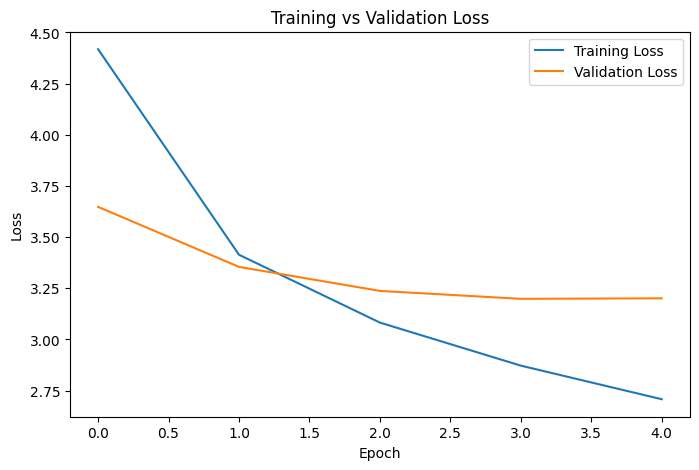

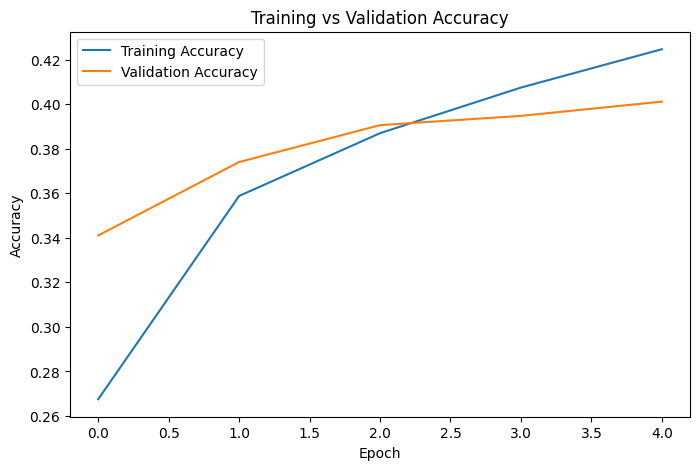

In [ ]:
test_loss, test_accuracy = model.evaluate(
    test_generator
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    history.history["masked_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_masked_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.show()

In [ ]:
index_word = tokenizer.index_word


def generate_caption(image_name):

    feature = feature_dict[
        image_name
    ]

    feature = np.expand_dims(
        feature.astype("float32"),
        axis=0
    )

    caption = ["startseq"]

    for _ in range(max_length):

        sequence = tokenizer.texts_to_sequences(
            [" ".join(caption)]
        )[0]

        sequence = pad_sequences(
            [sequence],
            maxlen=max_length,
            padding="post"
        )

        prediction = model.predict(
            [feature, sequence],
            verbose=0
        )

        position = len(caption) - 1

        predicted_id = np.argmax(
            prediction[0, position]
        )

        predicted_word = index_word.get(
            predicted_id,
            "<unk>"
        )

        if predicted_word == "endseq":
            break

        caption.append(
            predicted_word
        )

    return " ".join(
        caption[1:]
    )


# Test one image
test_image = test_images[0]

generated_caption = generate_caption(
    test_image
)

print("Image:", test_image)
print("Generated Caption:")
print(generated_caption)

Image: 3462165890_c13ce13eff.jpg
Generated Caption:
two children are walking on a street


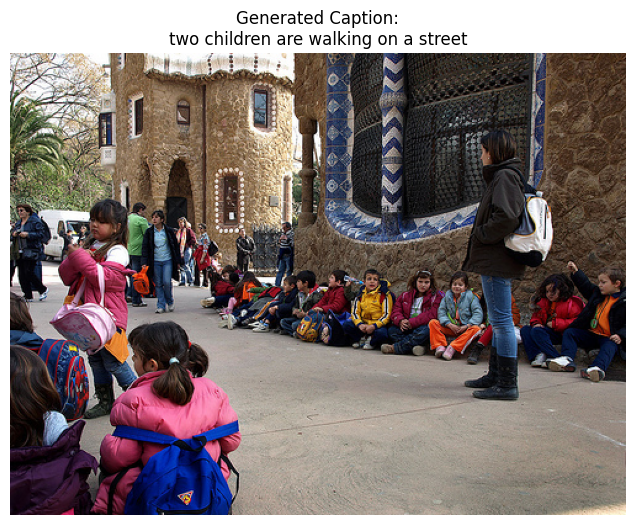

BLEU-1: 0.5156629281406259
BLEU-2: 0.32726260069282714
BLEU-3: 0.20215562661930891
BLEU-4: 0.13505007207020703


In [ ]:
from nltk.translate.bleu_score import sentence_bleu
from nltk.translate.bleu_score import SmoothingFunction

# Display image
image_path = os.path.join(
    IMAGE_DIR,
    test_image
)

image = Image.open(
    image_path
)

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title(
    "Generated Caption:\n" +
    generated_caption
)
plt.show()


# BLEU evaluation
smooth = SmoothingFunction().method1

bleu1_scores = []
bleu2_scores = []
bleu3_scores = []
bleu4_scores = []


# Evaluate first 100 test images
for image_name in test_images[:100]:

    generated = generate_caption(
        image_name
    )

    generated_tokens = generated.split()

    references = data[
        data["image"] == image_name
    ]["caption"].tolist()

    reference_tokens = []

    for reference in references:

        tokens = reference.split()

        tokens = [
            word
            for word in tokens
            if word not in [
                "startseq",
                "endseq"
            ]
        ]

        reference_tokens.append(
            tokens
        )


    bleu1_scores.append(
        sentence_bleu(
            reference_tokens,
            generated_tokens,
            weights=(1, 0, 0, 0),
            smoothing_function=smooth
        )
    )

    bleu2_scores.append(
        sentence_bleu(
            reference_tokens,
            generated_tokens,
            weights=(0.5, 0.5, 0, 0),
            smoothing_function=smooth
        )
    )

    bleu3_scores.append(
        sentence_bleu(
            reference_tokens,
            generated_tokens,
            weights=(1/3, 1/3, 1/3, 0),
            smoothing_function=smooth
        )
    )

    bleu4_scores.append(
        sentence_bleu(
            reference_tokens,
            generated_tokens,
            weights=(0.25, 0.25, 0.25, 0.25),
            smoothing_function=smooth
        )
    )


print("BLEU-1:", np.mean(bleu1_scores))
print("BLEU-2:", np.mean(bleu2_scores))
print("BLEU-3:", np.mean(bleu3_scores))
print("BLEU-4:", np.mean(bleu4_scores))

In [ ]:
# Save final trained model
final_weights = model.get_weights()

optimizers = {
    "SGD": tf.keras.optimizers.SGD(
        learning_rate=0.01,
        clipnorm=1.0
    ),

    "Momentum": tf.keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9,
        clipnorm=1.0
    ),

    "RMSprop": tf.keras.optimizers.RMSprop(
        learning_rate=0.001,
        clipnorm=1.0
    ),

    "Adam": tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    )
}


optimizer_results = {}

for name, opt in optimizers.items():

    print("\nTraining with:", name)

    # Start from same final trained model
    model.set_weights(final_weights)

    model.compile(
        optimizer=opt,
        loss=masked_loss,
        metrics=[masked_accuracy]
    )

    result = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=1,
        verbose=1
    )

    optimizer_results[name] = {
        "Training Loss": result.history["loss"][-1],
        "Validation Loss": result.history["val_loss"][-1],
        "Training Accuracy": result.history["masked_accuracy"][-1],
        "Validation Accuracy": result.history["val_masked_accuracy"][-1]
    }


# Restore final Adam-trained model
model.set_weights(final_weights)

print("\nOptimizer Comparison")
print(
    pd.DataFrame(optimizer_results).T
)


Training with: SGD
506/506 ━━━━━━━━━━━━━━━━━━━━ 39s 73ms/step - loss: 2.6648 - masked_accuracy: 0.4286 - val_loss: 3.1948 - val_masked_accuracy: 0.3994

Training with: Momentum
506/506 ━━━━━━━━━━━━━━━━━━━━ 40s 73ms/step - loss: 2.6389 - masked_accuracy: 0.4319 - val_loss: 3.1994 - val_masked_accuracy: 0.4001

Training with: RMSprop
506/506 ━━━━━━━━━━━━━━━━━━━━ 41s 75ms/step - loss: 2.6814 - masked_accuracy: 0.4263 - val_loss: 3.1954 - val_masked_accuracy: 0.3962

Training with: Adam
506/506 ━━━━━━━━━━━━━━━━━━━━ 42s 76ms/step - loss: 2.8196 - masked_accuracy: 0.4242 - val_loss: 3.2099 - val_masked_accuracy: 0.3956

Optimizer Comparison
          Training Loss  Validation Loss  Training Accuracy  \
SGD            2.664762         3.194810           0.428569   
Momentum       2.638899         3.199439           0.431945   
RMSprop        2.681399         3.195401           0.426341   
Adam           2.819553         3.209902           0.424157   

          Validation Accuracy  
SGD     

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 41586_2015_Article_BF528452a_Figg_HTML.jpg to 41586_2015_Article_BF528452a_Figg_HTML.jpg


In [ ]:
uploaded_image = list(uploaded.keys())[0]

image = Image.open(uploaded_image).convert("RGB")
image = image.resize((224, 224))

image_array = np.array(image)
image_array = np.expand_dims(image_array, axis=0)

image_array = preprocess_input(image_array)

new_feature = vgg.predict(image_array, verbose=0)

print("Original feature shape:", new_feature.shape)

Original feature shape: (1, 7, 7, 512)


In [ ]:
new_feature = new_feature.reshape(1, 49, 512)

In [ ]:
def caption_new_image(feature):

    caption = ["startseq"]

    for _ in range(max_length):

        sequence = tokenizer.texts_to_sequences(
            [" ".join(caption)]
        )[0]

        sequence = pad_sequences(
            [sequence],
            maxlen=max_length,
            padding="post"
        )

        prediction = model.predict(
            [feature, sequence],
            verbose=0
        )

        position = len(caption) - 1

        predicted_id = np.argmax(
            prediction[0, position]
        )

        predicted_word = index_word.get(
            predicted_id,
            "<unk>"
        )

        if predicted_word == "endseq":
            break

        caption.append(predicted_word)

    return " ".join(caption[1:])

In [ ]:
generated = caption_new_image(new_feature)

print("Generated Caption:")
print(generated)

Generated Caption:
a man in a black shirt is standing on a grassy path


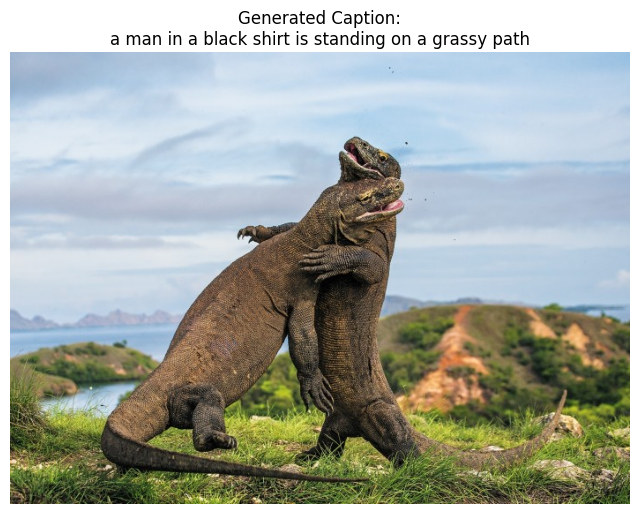

In [ ]:
plt.figure(figsize=(8, 6))
plt.imshow(Image.open(uploaded_image))
plt.axis("off")
plt.title("Generated Caption:\n" + generated)
plt.show()

Image: 3655074079_7df3812bc5.jpg
Generated Caption:
a woman in a pink dress and a woman in a pink dress and a woman in a pink dress and a woman in a white dress


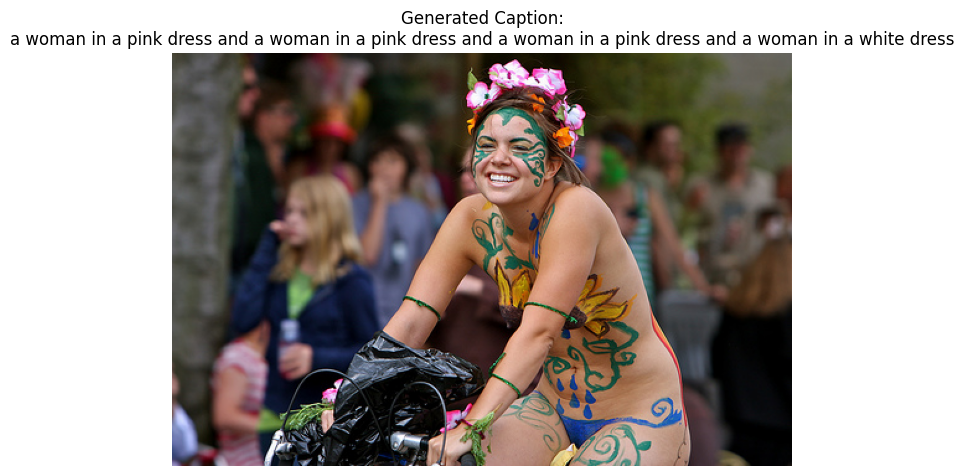

In [ ]:
# Test with an image from the Flickr8k test set

test_image = test_images[10]

print("Image:", test_image)

generated_caption = generate_caption(test_image)

print("Generated Caption:")
print(generated_caption)

plt.figure(figsize=(8, 6))
plt.imshow(Image.open(os.path.join(IMAGE_DIR, test_image)))
plt.axis("off")
plt.title("Generated Caption:\n" + generated_caption)
plt.show()

In [ ]:
history_more = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/10
506/506 ━━━━━━━━━━━━━━━━━━━━ 39s 77ms/step - loss: 2.4763 - masked_accuracy: 0.4529 - val_loss: 3.2692 - val_masked_accuracy: 0.4029 - learning_rate: 2.5000e-04
Epoch 2/10
506/506 ━━━━━━━━━━━━━━━━━━━━ 39s 77ms/step - loss: 2.3927 - masked_accuracy: 0.4637 - val_loss: 3.2818 - val_masked_accuracy: 0.4054 - learning_rate: 1.2500e-04


In [ ]:
def caption_new_image(feature):

    caption = ["startseq"]

    for _ in range(max_length):

        sequence = tokenizer.texts_to_sequences(
            [" ".join(caption)]
        )[0]

        sequence = pad_sequences(
            [sequence],
            maxlen=max_length,
            padding="post"
        )

        prediction = model.predict(
            [feature, sequence],
            verbose=0
        )

        position = len(caption) - 1

        # Get top 5 predictions
        probabilities = prediction[0, position]
        top_words = np.argsort(probabilities)[-5:][::-1]

        predicted_word = None

        for word_id in top_words:

            word = index_word.get(word_id, "<unk>")

            # Don't select end token immediately
            if word == "endseq":
                if len(caption) > 3:
                    predicted_word = word
                    break
                continue

            # Avoid repeating the same word
            if len(caption) > 1 and word == caption[-1]:
                continue

            predicted_word = word
            break

        if predicted_word is None or predicted_word == "endseq":
            break

        caption.append(predicted_word)

    return " ".join(caption[1:])

In [ ]:
generated = caption_new_image(new_feature)

print("Generated Caption:")
print(generated)

Generated Caption:
a dog is running in the grass


Generated Caption:
a dog is running in the grass


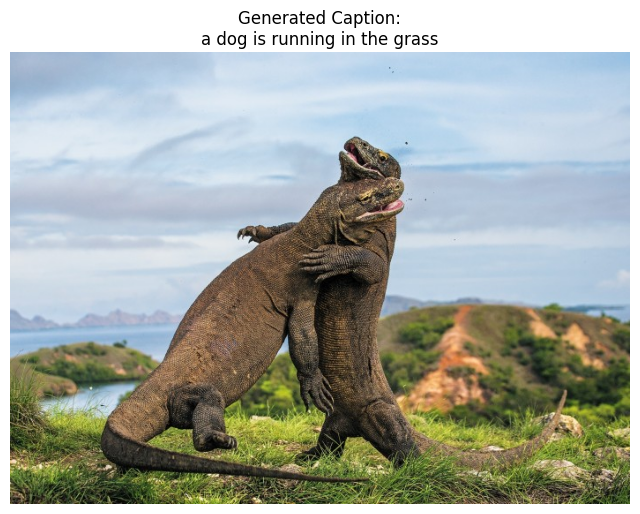

In [ ]:
generated = caption_new_image(new_feature)

print("Generated Caption:")
print(generated)

plt.figure(figsize=(8, 6))
plt.imshow(Image.open(uploaded_image))
plt.axis("off")
plt.title("Generated Caption:\n" + generated)
plt.show()

In [ ]:
# Continue training with a smaller learning rate

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005,
        clipnorm=1.0
    ),
    loss=masked_loss,
    metrics=[masked_accuracy]
)

early_stopping_2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr_2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=0.00001
)

history_extra = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,
    callbacks=[early_stopping_2, reduce_lr_2]
)

Epoch 1/15
506/506 ━━━━━━━━━━━━━━━━━━━━ 44s 77ms/step - loss: 2.4928 - masked_accuracy: 0.4558 - val_loss: 3.2584 - val_masked_accuracy: 0.4038 - learning_rate: 5.0000e-04
Epoch 2/15
506/506 ━━━━━━━━━━━━━━━━━━━━ 39s 76ms/step - loss: 2.4124 - masked_accuracy: 0.4649 - val_loss: 3.3140 - val_masked_accuracy: 0.4016 - learning_rate: 5.0000e-04
Epoch 3/15
506/506 ━━━━━━━━━━━━━━━━━━━━ 38s 76ms/step - loss: 2.3048 - masked_accuracy: 0.4780 - val_loss: 3.3415 - val_masked_accuracy: 0.4048 - learning_rate: 2.5000e-04
Epoch 4/15
506/506 ━━━━━━━━━━━━━━━━━━━━ 38s 76ms/step - loss: 2.2396 - masked_accuracy: 0.4869 - val_loss: 3.3577 - val_masked_accuracy: 0.4038 - learning_rate: 1.2500e-04


In [ ]:
def beam_search_caption(feature, beam_width=5):

    start_id = tokenizer.word_index["startseq"]
    end_id = tokenizer.word_index.get("endseq")

    beams = [
        ([start_id], 0.0)
    ]

    for _ in range(max_length):

        candidates = []

        for sequence, score in beams:

            # Stop expanding completed captions
            if sequence[-1] == end_id:
                candidates.append((sequence, score))
                continue

            text_sequence = [
                index_word.get(word_id, "<unk>")
                for word_id in sequence
            ]

            text = " ".join(text_sequence)

            input_sequence = tokenizer.texts_to_sequences([text])[0]

            input_sequence = pad_sequences(
                [input_sequence],
                maxlen=max_length,
                padding="post"
            )

            prediction = model.predict(
                [feature, input_sequence],
                verbose=0
            )

            position = len(sequence) - 1

            probabilities = prediction[0, position]

            # Get top beam_width words
            top_ids = np.argsort(probabilities)[
                -beam_width:
            ][::-1]

            for word_id in top_ids:

                word_id = int(word_id)

                # Avoid immediate repeated words
                if (
                    len(sequence) > 1
                    and word_id == sequence[-1]
                ):
                    continue

                probability = float(
                    probabilities[word_id]
                )

                if probability <= 0:
                    continue

                new_sequence = sequence + [word_id]

                new_score = score + np.log(
                    probability + 1e-10
                )

                candidates.append(
                    (new_sequence, new_score)
                )

        # Keep best sequences
        candidates.sort(
            key=lambda x: x[1] / (len(x[0]) ** 0.7),
            reverse=True
        )

        beams = candidates[:beam_width]

        # Stop if all beams finished
        if all(
            seq[-1] == end_id
            for seq, score in beams
        ):
            break

    best_sequence = beams[0][0]

    words = []

    for word_id in best_sequence[1:]:

        if word_id == end_id:
            break

        word = index_word.get(
            word_id,
            "<unk>"
        )

        words.append(word)

    return " ".join(words)

Image: 2806632713_edd6f6c893.jpg
Generated Caption:
a man is climbing a rope


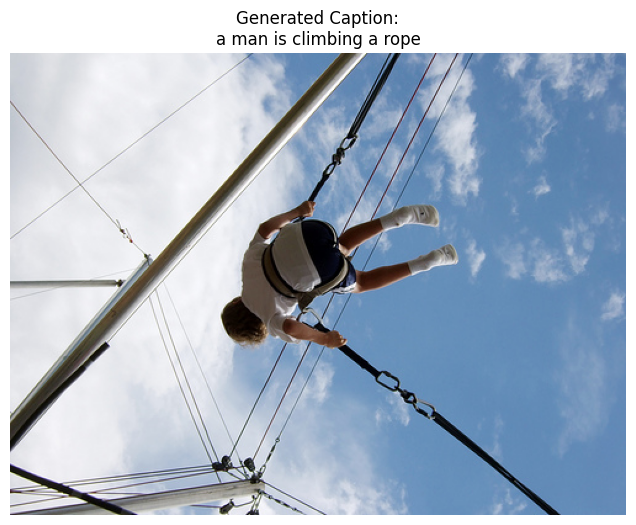

In [ ]:
test_image = test_images[20]

feature = feature_dict[test_image]
feature = np.expand_dims(
    feature.astype("float32"),
    axis=0
)

generated = beam_search_caption(feature, beam_width=5)

print("Image:", test_image)
print("Generated Caption:")
print(generated)

plt.figure(figsize=(8, 6))
plt.imshow(
    Image.open(os.path.join(IMAGE_DIR, test_image))
)
plt.axis("off")
plt.title("Generated Caption:\n" + generated)
plt.show()

In [ ]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

smooth = SmoothingFunction().method1

bleu1_scores = []
bleu2_scores = []
bleu3_scores = []
bleu4_scores = []

# Test only 10 images
for image_name in test_images[:10]:

    feature = feature_dict[image_name]
    feature = np.expand_dims(
        feature.astype("float32"),
        axis=0
    )

    # Generate caption
    generated = beam_search_caption(
        feature,
        beam_width=5
    )

    generated_tokens = generated.split()

    # Reference captions
    references = data[
        data["image"] == image_name
    ]["caption"].tolist()

    reference_tokens = []

    for reference in references:
        tokens = reference.split()

        tokens = [
            word for word in tokens
            if word not in ["startseq", "endseq"]
        ]

        reference_tokens.append(tokens)

    # BLEU-1
    bleu1 = sentence_bleu(
        reference_tokens,
        generated_tokens,
        weights=(1, 0, 0, 0),
        smoothing_function=smooth
    )

    # BLEU-2
    bleu2 = sentence_bleu(
        reference_tokens,
        generated_tokens,
        weights=(0.5, 0.5, 0, 0),
        smoothing_function=smooth
    )

    # BLEU-3
    bleu3 = sentence_bleu(
        reference_tokens,
        generated_tokens,
        weights=(1/3, 1/3, 1/3, 0),
        smoothing_function=smooth
    )

    # BLEU-4
    bleu4 = sentence_bleu(
        reference_tokens,
        generated_tokens,
        weights=(0.25, 0.25, 0.25, 0.25),
        smoothing_function=smooth
    )

    bleu1_scores.append(bleu1)
    bleu2_scores.append(bleu2)
    bleu3_scores.append(bleu3)
    bleu4_scores.append(bleu4)

    print("Completed:", image_name)


print("\nImproved BLEU Scores")
print("--------------------")
print("BLEU-1:", np.mean(bleu1_scores))
print("BLEU-2:", np.mean(bleu2_scores))
print("BLEU-3:", np.mean(bleu3_scores))
print("BLEU-4:", np.mean(bleu4_scores))

Completed: 3462165890_c13ce13eff.jpg
Completed: 3365348059_9773165302.jpg
Completed: 2325816912_b3bb41cdbb.jpg
Completed: 2895700779_fac1d9d278.jpg
Completed: 2901880865_3fd7b66a45.jpg
Completed: 3737492755_bcfb800ed1.jpg
Completed: 2649705487_4605e879e9.jpg
Completed: 2085557551_7a88d01d4e.jpg
Completed: 426065353_e9a604a01f.jpg
Completed: 405961988_fcfe97f31e.jpg

Improved BLEU Scores
--------------------
BLEU-1: 0.6265301365301366
BLEU-2: 0.3825508793487469
BLEU-3: 0.23376347304919998
BLEU-4: 0.16752218960678883


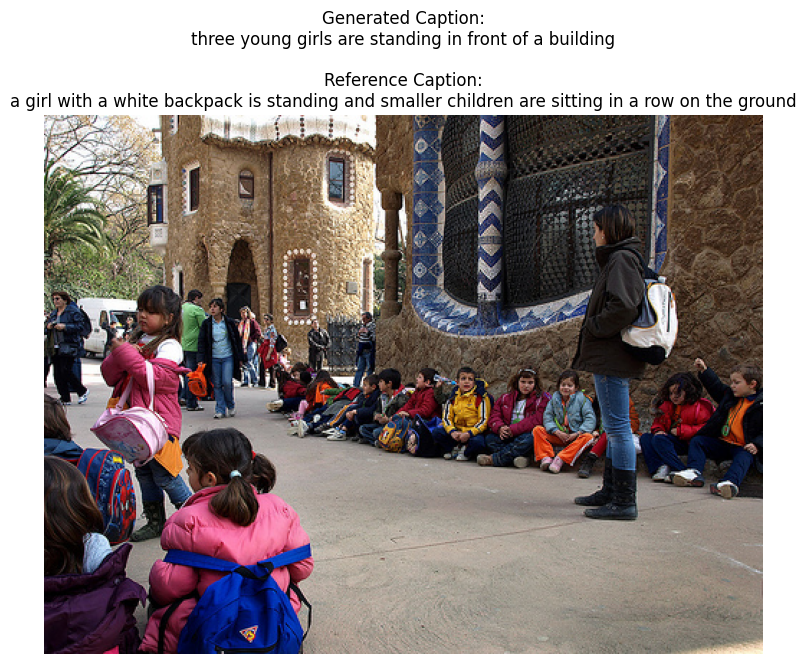

IMAGE: 3462165890_c13ce13eff.jpg
GENERATED: three young girls are standing in front of a building
REFERENCE: a girl with a white backpack is standing and smaller children are sitting in a row on the ground


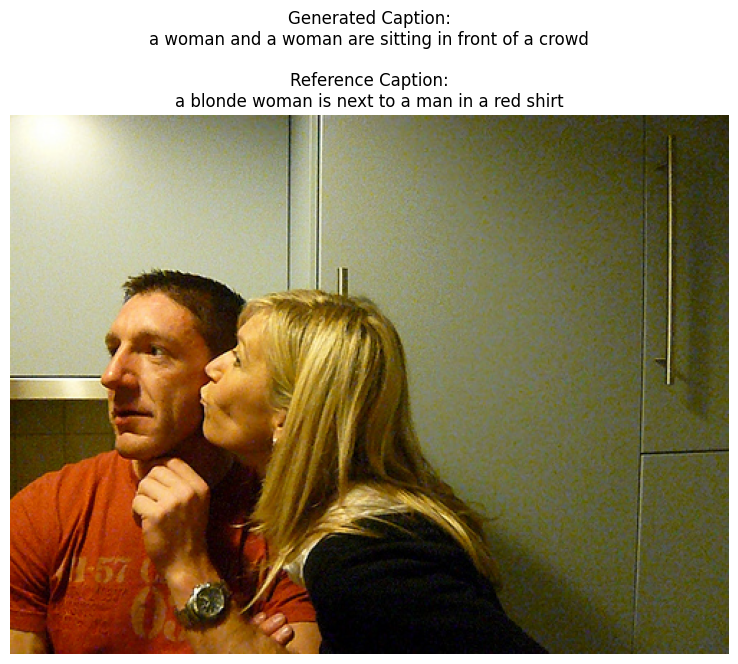

IMAGE: 3365348059_9773165302.jpg
GENERATED: a woman and a woman are sitting in front of a crowd
REFERENCE: a blonde woman is next to a man in a red shirt


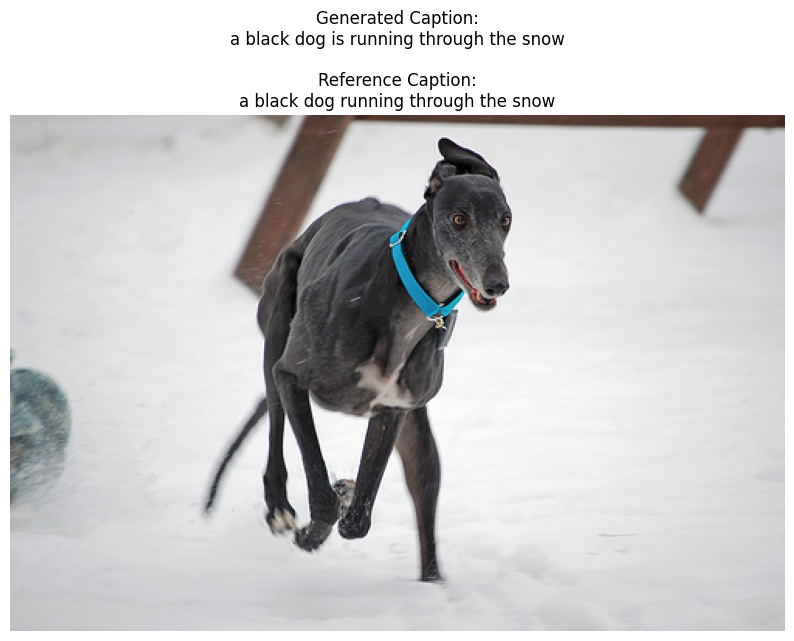

IMAGE: 2325816912_b3bb41cdbb.jpg
GENERATED: a black dog is running through the snow
REFERENCE: a black dog running through the snow


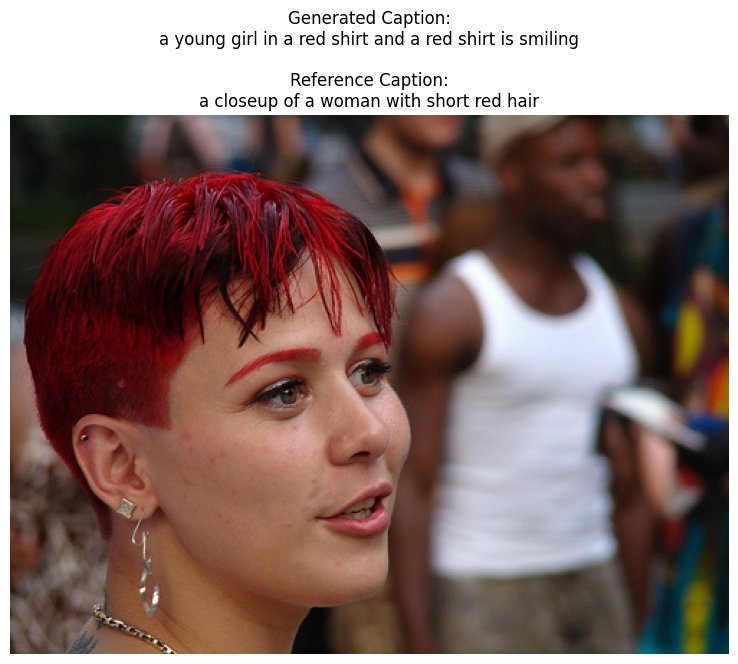

IMAGE: 2895700779_fac1d9d278.jpg
GENERATED: a young girl in a red shirt and a red shirt is smiling
REFERENCE: a closeup of a woman with short red hair


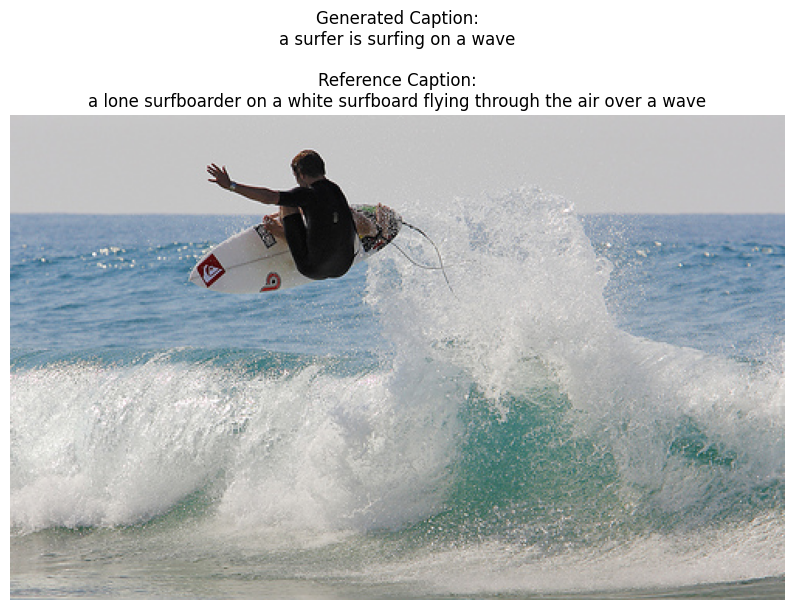

IMAGE: 2901880865_3fd7b66a45.jpg
GENERATED: a surfer is surfing on a wave
REFERENCE: a lone surfboarder on a white surfboard flying through the air over a wave


In [ ]:
# Final demonstration: 5 test images with generated captions

import matplotlib.pyplot as plt
from PIL import Image

# Select 5 unseen test images
demo_images = test_images[:5]

for i, image_name in enumerate(demo_images):

    # Get image features
    feature = feature_dict[image_name]
    feature = np.expand_dims(
        feature.astype("float32"),
        axis=0
    )

    # Generate caption using Beam Search
    generated = beam_search_caption(
        feature,
        beam_width=5
    )

    # Get reference captions
    references = data[
        data["image"] == image_name
    ]["caption"].tolist()

    # Remove start/end tokens
    references = [
        caption.replace("startseq ", "")
                .replace(" endseq", "")
        for caption in references
    ]

    # Display image
    plt.figure(figsize=(10, 7))

    image_path = os.path.join(
        IMAGE_DIR,
        image_name
    )

    plt.imshow(Image.open(image_path))
    plt.axis("off")

    plt.title(
        "Generated Caption:\n"
        + generated
        + "\n\nReference Caption:\n"
        + references[0],
        fontsize=12
    )

    plt.show()

    print("=" * 80)
    print("IMAGE:", image_name)
    print("GENERATED:", generated)
    print("REFERENCE:", references[0])
    print("=" * 80)